**Project Name:** Predicting oil and gas plant technologies based on data from the Global Energy Monitor's Global Oil and Gas Plant Tracker

**Data source:** Global Energy Monitor, Global Oil and Gas Plant Tracker, August 2026 (CC BY 4.0).

**Background:** The power generation sector has become an essential sector of modern society considering the current generation's inescapable reliance on electricity. Within the sector,the oil and gas subsector comprises a significant share of global power generation, making it a key player whose movements cannot be overlooked. However, the subsector brings with it its own hosts of problems due to its traditional association with non-renewable means of producing power. These include introducing pollution, causing resource depletion, and significantly contributing to global warming, to name a few. 

As such, it is important to have as much information as possible to ensure that regulators and decision-makers put proper guardrails in place for this subsector, while not compromising the satisfaction of humanity's energy needs. However, not all data sources are perfect, and even the best sources can lack important information that may be required to properly manage them.

**About the data set:** The Global Oil and Gas Plant Tracker maintained by the Global Energy Monitor (GEM) is a publicly available worldwide dataset of oil- and gas-fired power plants. Its latest update was published in August 2026, and it is the version of the data set used for this project. This project explores the dataset and assesses how machine learning can be used to help improve it.

In [103]:
#Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mutual_info_score, accuracy_score, f1_score, classification_report
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [104]:
#Loading the data, which can be found in one specific sheet of the excel file:
df = pd.read_excel('data/Global Oil and Gas Plant Tracker (GOGPT) - August 2026.xlsx', sheet_name='Gas & Oil Units')
df.shape

(14099, 46)

In [105]:
#Checking what the dataset entries look like:
df.head().T

,0,1,2,3,4
Wiki URL,https://www.gem.wiki/Azizi_Energy_power_station,https://www.gem.wiki/Bayat_IPP_power_station,https://www.gem.wiki/Bayat_IPP_power_station,https://www.gem.wiki/Mazar_IPP_power_station,https://www.gem.wiki/North_West_Kabul_thermal_...
Country/Area,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan
Plant name,Azizi Energy power station,Bayat IPP power station,Bayat IPP power station,Mazar IPP power station,North West Kabul thermal power plant
Plant Name in Local Language / Script,NaN,NaN,NaN,NaN,NaN
Other Name(s),NaN,NaN,NaN,Mazar-e-Sharif power station,NaN
Unit name,1,Phase 2,Phase 3,1,1
Fuel,"fossil gas: natural gas, fossil liquids: fuel oil",fossil gas: natural gas,fossil gas: natural gas,fossil gas: natural gas,fossil liquids: fuel oil
Capacity (MW),3700.0,80.0,80.0,59.0,95.0
Status,pre-construction,announced,announced,shelved,operating
Turbine/Engine Technology,unknown,gas turbine,gas turbine,internal combustion,steam turbine


Based only off of the first entry, the column Turbine/Engine Technology is an interesting would-be target because it is unknown in spite of its importance. It is interesting because it dictates what kind of plant the facility will be and what processes specifically will be employed in the course of power generation.

In [106]:
#Checking all possible values of the target column:
df['Turbine/Engine Technology'].value_counts()

Turbine/Engine Technology
combined cycle         5390
gas turbine            4493
steam turbine          2823
internal combustion     727
unknown                 426
ICCC                    224
ISCC                      9
AFC                       7
Name: count, dtype: int64

There are 426 entries in the data set where it is unknown, and 13673 entries where it is a known value. Also, three of the technologies (ICCC, ISCC, AFC) are relatively rare (they only make up 1.7% of the data) and it may for simplicity's sake be better to exclude them for the purpose of this exercise.

In [107]:
#Retaining only entries wherein technology is combined cycle, gas turbine, steam turbine, or internal combustion:
df = df[df['Turbine/Engine Technology'].isin(['combined cycle', 'gas turbine', 'steam turbine', 'internal combustion'])]
df = df.reset_index(drop=True)
len(df)

13433

In [108]:
#Showing percentages of possible values:
df['Turbine/Engine Technology'].value_counts(normalize=True)

Turbine/Engine Technology
combined cycle         0.401251
gas turbine            0.334475
steam turbine          0.210154
internal combustion    0.054120
Name: proportion, dtype: float64

The biggest class is combined cycle with 40%, and the smallest is internal combustion with only 5%. Because of this imbalance, a good approach would be to compare models using macro F1 (as will be seen later).

As for the other features in the dataset, it is necessary to determine which to include in the model and which to exclude. For some of these, it is explanatory as to why they warrant being left out. For instance, the following are naming/identifying metadata that are unlikely to influence the possible technology type of a plant:

* Wiki URL
* Plant name
* Plant Name in Local Language / Script
* Other Name(s)
* Unit name
* Operator(s)
* Owner(s)
* Owner(s) GEM Entity ID
* Parent(s)
* Parent GEM Entity ID
* Other IDs (location)
* GEM unit ID

Note: while the GEM location ID column is also technically an identifier, it is retained because of its ability to keep duplicate units within the same plant together (a fact that will prove useful when dividing into train and test datasets).

Others are also redundant. For example, since exact latitude and longitude are also given in the dataset, the following location-dependent columns may be dropped:

* City
* Local area (taluk, county)
* Major area (prefecture, district)
* State/Province
* Subregion
* Region
* Country/Area
* Location accuracy

Finally, others only provide technical information that do not reasonably influence the turbine/engine technology type:

* Status - describes whether the plant is operating, being constructed, etc.
* Fuel - although important, another column (fuel classification) already captures the type of fuel used by the plant and offers only four possible values (Gas, Multi Fuel, Oil, LNG only) instead of this column's 241 distinct values.

For the remaining features, a worthwhile check would be to see which are mostly empty and will therefore not be that contributory to the model. As an assumption, a feature would be considered too empty if half or more than half of the entries do not have a value for it.

In [109]:
#Creating a table of the dataset showing the percentage of missing values and the data type of each column:
summary = pd.DataFrame({
    'missing_%': (df.isnull().mean() * 100).round(),
    'type': df.dtypes.astype(str),
})

#Listing the target column and all the others that we reasoned are not necessary:
exclude_col = ['Turbine/Engine Technology', 'Wiki URL', 'Plant name', 'Plant Name in Local Language / Script', 'Other Name(s)', 'Unit name', 'Operator(s)', 'Owner(s)', 'Owner(s) GEM Entity ID', 'Parent(s)', 'Parent GEM Entity ID', 'Other IDs (location)', 'GEM unit ID', 'City', 'Local area (taluk, county)', 'Major area (prefecture, district)', 'State/Province', 'Subregion', 'Region', 'Country/Area', 'Location accuracy','Status', 'Fuel']

#Seeing which columns have more than 50% missing values and determine which columns will remain:
text_cols = [c for c in df.select_dtypes(exclude='number').columns if c not in exclude_col]
num_cols = [c for c in df.select_dtypes(include='number').columns if c not in exclude_col]

text_candidates = [c for c in text_cols if c not in summary.index[summary['missing_%'] > 50].tolist()]
num_candidates = [c for c in num_cols if c not in summary.index[summary['missing_%'] > 50].tolist()]

print('Text candidates:', text_candidates)
print('Numeric candidates:', num_candidates)

Text candidates: ['CHP', 'GEM location ID', 'Fuel classification']
Numeric candidates: ['Capacity (MW)', 'Start year', 'Latitude', 'Longitude']


This leaves us with 1 identifier column, 2 categorical columns, and 4 numerical columns, that along with the target column, brings the final dataset down to 8 columns. 

In [110]:
#Preparing the smaller dataset with only the target column and the selected features:
df = df[text_candidates + num_candidates + ['Turbine/Engine Technology']]
df

,CHP,GEM location ID,Fuel classification,Capacity (MW),Start year,Latitude,Longitude,Turbine/Engine Technology
0,NaN,L100000408997,Gas,80.0,NaN,36.692494,65.985089,gas turbine
1,NaN,L100000408997,Gas,80.0,NaN,36.692494,65.985089,gas turbine
2,not found,L100000408316,Gas,59.0,NaN,36.703200,67.135560,internal combustion
3,NaN,L100001047131,Oil,95.0,NaN,34.718110,69.307594,steam turbine
4,not found,L100000408996,Multi Fuel,105.0,2009.0,34.561557,69.294854,internal combustion
...,...,...,...,...,...,...,...,...
13428,not found,L100000407859,Gas,60.0,NaN,12.824678,44.919038,gas turbine
13429,not found,L100000407861,Gas,150.0,NaN,15.760619,48.002014,gas turbine
13430,not found,L100000406833,Gas,400.0,NaN,-10.538525,32.073014,combined cycle
13431,not found,L100000406833,Gas,800.0,NaN,-10.538525,32.073014,combined cycle


In [111]:
#Renaming columns for simplicity:
df.columns = ['chp', 'plant_id', 'fuel', 'capacity_mw', 'start_year', 'latitude', 'longitude', 'technology']

In [112]:
#Checking for missing values:
df.isnull().sum()

chp            1309
plant_id          0
fuel              0
capacity_mw       0
start_year     1889
latitude          0
longitude         0
technology        0
dtype: int64

In [113]:
#Assessing possible values for chp:
df.chp.value_counts()

chp
not found    5439
yes          3523
no           3162
Name: count, dtype: int64

In [114]:
#Filling blanks with "not found" as it is effectively equivalent to unknown:
df.chp = df.chp.fillna('not found')

In [115]:
#Filling blanks in start_year with 0 to signify unknown - the median value would not make sense for year info:
df.start_year = df.start_year.fillna(0)

In [116]:
#Cleaning values under all remaining categorical columns:
for c in ['chp', 'fuel', 'technology']:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [117]:
#Assembling the categorical and numerical lists:
categorical=['chp', 'fuel']
numerical=['capacity_mw', 'start_year', 'latitude', 'longitude']

With the data cleaned, an exploration of the data is in order.

In [118]:
#Describing the numerical features:
df[numerical].describe().round(1)

,capacity_mw,start_year,latitude,longitude
count,13433.0,13433.0,13433.0,13433.0
mean,280.0,1722.9,31.3,10.1
std,314.9,697.2,18.5,80.9
min,20.0,0.0,-51.6,-158.1
25%,80.0,1979.0,24.7,-79.8
50%,158.0,2003.0,33.9,24.3
75%,400.0,2017.0,41.4,69.4
max,6342.0,2041.0,71.0,175.2


For start year, the latest is 2041 which tells us that the dataset includes planned facilities as well as operational ones. The 0s as established earlier represent those plants where we do not know the start year.

Latitude/longitude values just show us physical location, but from the min and max values we can see that the covered plants span virtually the whole world. Latitude runs from -51.6 (e.g., Santa Cruz in Argentina) to 71 (e.g., Greenland) whereas longitude spans -158.1 (e.g., Alaska) to 175. 2 (e.g., Chukotka Autonomous Okrug).

Finally, capacity ranges from 20 MW to 6342 MW. Because the median is 158 MW and the mean is 280 MW, this tells us that there are a few units with very high MW values that bring this average up. A box plot will help illustrate how these capacity values are distributed across the four technologies.

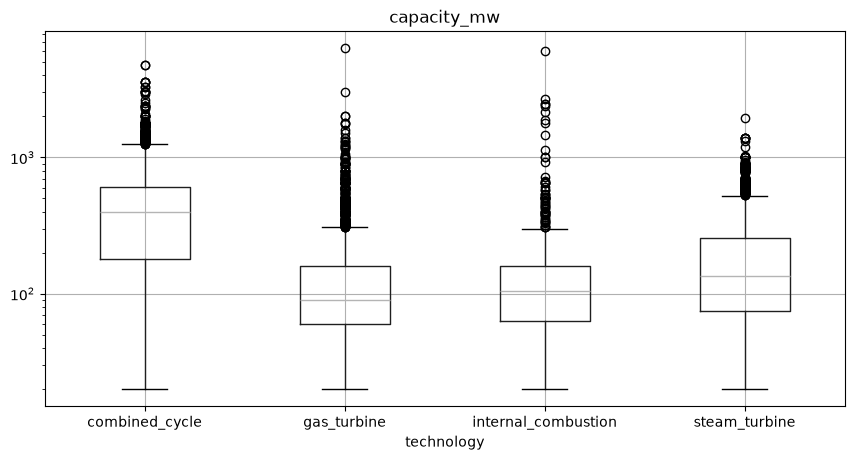

In [119]:
#Boxplotting the capacity:
df.boxplot(column='capacity_mw', by='technology', figsize=(10, 5))
plt.yscale('log')
plt.suptitle('')
plt.show()

This shows us that combined cycle units have the highest typical capacity across the four technologies.

Another interesting relationship to explore would be fuel and technology type:

In [120]:
#Checking technology against fuel type:
pd.crosstab(df.fuel, df.technology, normalize='index').round(2)

technology,combined_cycle,gas_turbine,internal_combustion,steam_turbine
fuel,,,,
gas,0.48,0.34,0.03,0.15
lng_only,0.89,0.04,0.01,0.05
multi_fuel,0.24,0.38,0.03,0.35
oil,0.04,0.35,0.30,0.31


This shows us that fuel is an essential feature to include in the model. Some interesting characteristics:
* Nearly half of gas plants (48%) are combined cycle
* The majority (89%) of plants using LNG only are combined cycle
* About a third of multi-fuel plants employ gas turbines (38%), and another third use steam turbines (35%)
* Oil plants are nearly evenly split across gas turbines, internal combustion, and steam turbines, and are rarely combined cycle (4%)

With this, it is time to split the data. However, an important consideration observable in the data is the fact that many of the units are duplicated, i.e., one plant can contain multiple units with the same information. This can be observed in the 2nd and 3rd entries when initially running df.head().T.

It is therefore important to make sure that the data is split across plants (i.e., by rows with the same plant_id), and not across units (i.e., by each row of the dataset). If this is not done, it will be possible for similar units to be sent to both training and test sets separately, and that would cause the model to 'memorize' the correct answer to something that it will see in the test set.

In [121]:
plants = df.plant_id.unique()

#Splitting 80/20, and seeding with 42 for reproducibility:
plants_full_train, plants_test = train_test_split(plants, test_size=0.2, random_state=42)

df_full_train = df[df.plant_id.isin(plants_full_train)].reset_index(drop=True)
df_test = df[df.plant_id.isin(plants_test)].reset_index(drop=True)

len(df_full_train), len(df_test)

(10771, 2662)

For modeling, a number of models will be tested to determine the best one. Before that, it is worth trying feature analysis to see how the features influence the technology type.

In [122]:
#Checking mutual information for the categorical features:
for c in categorical:
    print(c, round(mutual_info_score(df_full_train[c], df_full_train.technology), 3))

chp 0.063
fuel 0.116


The fuel value of 0.116 being higher than the chp value of 0.063 tells us that fuel is more influential. Also, since both values are positive, this tells us that both are indeed contributory to a meaningful prediction.

As for numerical features:

In [123]:
#Checking the median of numerical features for plants with a valid start year:
df_full_train[df_full_train.start_year > 0].groupby('technology')[numerical].median()

,capacity_mw,start_year,latitude,longitude
technology,,,,
combined_cycle,390.00,2012.0,33.487142,33.289861
gas_turbine,89.00,2005.0,33.963600,-68.181100
internal_combustion,100.10,2018.0,23.075451,14.147120
steam_turbine,132.25,1984.0,39.166628,39.060800


Some important observations :
* Plants with high capacities are most likely to be combined cycle
* Steam turbine is the oldest technology, and internal combustion is the newest
* Latitude/longitude is a lot more variable and more informational, but gives us a rough sketch of how plant technologies vary by location. For instance, gas turbines are mostly found in the Americas (-68.18) whereas the other technologies are more prevalent farther East (around Ukraine/Egypt for combined cycle, central Europe for internal combustion, and Turkey for steam turbine)

This tells us that these chosen features significantly influence what the predicted technology will be.

In [124]:
#Generating the train function:
def train(df_train, y_train, model):
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model.fit(X_train, y_train)
    return dv, model

In [125]:
#Generating the predict function:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict(X)
    return y_pred

In [126]:
#Generating the cross-validation function to determine the macro F1 score and stdev for a given model:

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def cross_validate(model):
    scores=[]

    for train_idx, val_idx in kfold.split(plants_full_train):
        df_train = df_full_train[df_full_train.plant_id.isin(plants_full_train[train_idx])]
        df_val=df_full_train[df_full_train.plant_id.isin(plants_full_train[val_idx])]

        dv, model = train(df_train, df_train.technology.values, model)
        
        y_pred=predict(df_val, dv, model)
        scores.append(f1_score(df_val.technology.values, y_pred, average='macro'))

    return np.mean(scores), np.std(scores)

In [127]:
#Testing a linear model first using Logistic Regression with differing values of C:
for C in [0.01, 0.1, 1, 10, 100, 1000]:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    mean_f1, std_f1 = cross_validate(model)
    print(f'C={C}: Macro F1={mean_f1:.3f}, Std F1={std_f1:.3f}')

C=0.01: Macro F1=0.530, Std F1=0.021
C=0.1: Macro F1=0.546, Std F1=0.019
C=1: Macro F1=0.547, Std F1=0.019
C=10: Macro F1=0.548, Std F1=0.019
C=100: Macro F1=0.548, Std F1=0.019
C=1000: Macro F1=0.548, Std F1=0.019


The linear model's best score is 0.548 when C is 10.
Three tree-based models will also be tested: Decision Tree, Random Forest, and Gradient Boosting.

In [128]:
#Testing three tree-based models and figuring out the best maximum depth for each:
results = []

for max_depth in [3, 5, 7, 10]:
    models={
        'Decision Tree': DecisionTreeClassifier(max_depth=max_depth, random_state=42),
        'Random Forest': RandomForestClassifier(max_depth=max_depth, random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(max_depth=max_depth, random_state=42)
    }

    for model_name, model in models.items():
        mean_f1, std_f1 = cross_validate(model)
        results.append((model_name, max_depth, mean_f1, std_f1))
        print(f'Model={model_name}, Max Depth={max_depth}, Macro F1={mean_f1:.3f}, Std F1={std_f1:.3f}')

Model=Decision Tree, Max Depth=3, Macro F1=0.492, Std F1=0.019
Model=Random Forest, Max Depth=3, Macro F1=0.546, Std F1=0.021
Model=Gradient Boosting, Max Depth=3, Macro F1=0.728, Std F1=0.020
Model=Decision Tree, Max Depth=5, Macro F1=0.622, Std F1=0.031
Model=Random Forest, Max Depth=5, Macro F1=0.641, Std F1=0.024
Model=Gradient Boosting, Max Depth=5, Macro F1=0.750, Std F1=0.015
Model=Decision Tree, Max Depth=7, Macro F1=0.678, Std F1=0.023
Model=Random Forest, Max Depth=7, Macro F1=0.704, Std F1=0.021
Model=Gradient Boosting, Max Depth=7, Macro F1=0.755, Std F1=0.006
Model=Decision Tree, Max Depth=10, Macro F1=0.693, Std F1=0.024
Model=Random Forest, Max Depth=10, Macro F1=0.731, Std F1=0.022
Model=Gradient Boosting, Max Depth=10, Macro F1=0.750, Std F1=0.012


For this particular dataset, Gradient Boosting at max_depth=7 gives the best Macro F1 score compared to the other options (logistic regression, random forest, and decision tree), and so it is a good basis for choosing it as the final model.

The final step would be to test the selected model on the test set and see how it performs.

In [129]:
#Applying Gradient Boosting to the test set:
y_train = df_full_train.technology.values
y_test = df_test.technology.values

dv, model = train(df_full_train, y_train, GradientBoostingClassifier(max_depth=7, random_state=42))
y_pred = predict(df_test, dv, model)

print('Accuracy=', round(accuracy_score(y_test, y_pred), 3))
print('Macro F1=', round(f1_score(y_test, y_pred, average='macro'), 3))

#As a baseline, we can check the accuracy if it guesses combined_cycle always (which should be around 40%)
print("Always Guess Combined Cycle=", round((y_test == 'combined_cycle').mean(), 3))


Accuracy= 0.828
Macro F1= 0.778
Always Guess Combined Cycle= 0.388


We get a macro f1 score of 0.778 based on the test set. The accuracy of 0.828 versus the baseline of 0.388 shows that using this model is indeed significantly better than just guessing combined cycle every time.

In [130]:
#Running a classification report to see the precision, recall, and F1 score for each class:
print(classification_report(y_test, y_pred))

                     precision    recall  f1-score   support

     combined_cycle       0.84      0.91      0.87      1034
        gas_turbine       0.81      0.82      0.81       874
internal_combustion       0.62      0.59      0.60       146
      steam_turbine       0.90      0.76      0.83       608

           accuracy                           0.83      2662
          macro avg       0.79      0.77      0.78      2662
       weighted avg       0.83      0.83      0.83      2662



The classification report shows relatively high scores for combined_cycle, gas_turbine, and steam_turbine, but suffers at internal_combustion. This may be attributed to its natural rarity in the dataset.

A few more confirmatory tests with the other tree-based models to prove that Gradient Boosting at max_depth=7 is the best one to use:

In [131]:
#Applying Random Forest to the test set, just for comparison:
y1_train = df_full_train.technology.values
y1_test = df_test.technology.values

dv1, model1 = train(df_full_train, y1_train, RandomForestClassifier(max_depth=10, random_state=42))
y1_pred = predict(df_test, dv1, model1)

print('Accuracy=', round(accuracy_score(y1_test, y1_pred), 3))
print('Macro F1=', round(f1_score(y1_test, y1_pred, average='macro'), 3))

Accuracy= 0.808
Macro F1= 0.76


In [132]:
#Applying Decision Tree to the test set, just for comparison:
y2_train = df_full_train.technology.values
y2_test = df_test.technology.values

dv2, model2 = train(df_full_train, y2_train, DecisionTreeClassifier(max_depth=10, random_state=42))
y2_pred = predict(df_test, dv2, model2)

print('Accuracy=', round(accuracy_score(y2_test, y2_pred), 3))
print('Macro F1=', round(f1_score(y2_test, y2_pred, average='macro'), 3))

Accuracy= 0.772
Macro F1= 0.714


The other tree-based models perform less favorably on the test set, as predicted. As such, Gradient Boosting is what will be used.

As a last check, we can confirm how the final model treats the importance of each of the features via permutation importance.

In [133]:
#Running permutation importance of the final model on the test set:
X_test = dv.transform(df_test[categorical + numerical].to_dict(orient='records'))

result = permutation_importance(model, X_test, y_test, scoring='f1_macro', n_repeats=5, random_state=42)
pd.Series(result.importances_mean, index=dv.get_feature_names_out()).sort_values(ascending=False).round(3)

capacity_mw        0.206
start_year         0.195
longitude          0.143
fuel=oil           0.104
latitude           0.088
chp=yes            0.024
chp=no             0.018
fuel=gas           0.009
fuel=multi_fuel    0.006
fuel=lng_only      0.002
chp=not_found     -0.000
dtype: float64

This confirms the importance of the selected features in making the prediction. As predicted, capacity is the most important as it leads with 0.206, and it is followed closely by start_year at 0.195. 

With this completed, the other Python scripts continue the work established through this notebook:
* train.py - for training the final model and saving it to a file
* predict.py - for loading the final model and serving it via a web service